In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np

from image_util import PROJECT_ROOT, load_image_matrix, load_image_vector
from network import Network

# Introduction

Work in this notebook is part of the exam for the course "Math Concepts for Developers". Topic that will be covered in this notebook is "Introduction to Structure of Neural Networks. Overview of common algorithms used in training neural networks".  

## Why this topic?

As software engineer by heart I would like to explore and gain deeper understanding on the subject by implementing things from scratch. I believe that this will help me to understand the subject better and will help me to implement more complex algorithms in the future. Once I have neural network I can use it as foundation to implement more complex ML and DL solutions.

## Objectives
- Implement and explain simplest neural network from scratch.
- Run example and analyze results.
- Experiment with number of hidden layers and number of neurons in each layer and analyze results.

# Problem Formulation

## Real-world problem

Computers receive text and numbers as pictures all the time: scanned forms, photographed cheques, parcel labels, house numbers, meter readings. A person reads a digit in such an image without effort, but for a program an image is only a grid of brightness values.

## Why not write the rules by hand?

The same digit can look very different: another font or size, rotation or position. Writing explicit rules such as "a 0 is a closed loop" quickly breaks on such variations. Instead of hand-written rules, we let a model **learn** the rules from many labelled examples. A neural network is one such model.

## The task in this notebook

**Input:** a grayscale image of one digit, 28x28 pixels.

**Output:** which of the 10 digits ($0 \ldots 9$) is on the image.

The mathematical version of this problem is covered in the next section.

# TODO Methods

Explain What LM will be used for. In this case will recognise letters. First test will be with typed numbers and second test will be with handwritten numbers.

# Implementation of simple neural network

In order to have neural network first we need to have neurons. Neuron will hold number which is also called "Activation". Number in in the first layer of the network will correspond to pixel of image with size 28x28. Number range will be from $ [0, 1] $. Where $0$ is black and $1$ is white. All image neurons will be first layer of the neural network. 

Matrix shape: (28, 28)
[[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.1 0.6 0.9 1.  0.9 0.7 0.2 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.2 0.9 1.  1.  1.  1.  1.  1.  0.4 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.1 0.9 1.  0.8 0.2 0.  0.1 0.7 1.  1.  0.2 0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.5 1.  1.  0.1 0.  0. 

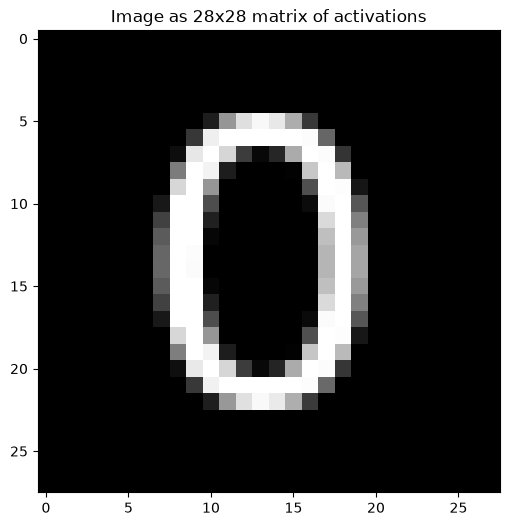

Vector shape: (784, 1)
[[0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0. ]
 [0.

In [2]:
image_path = "exam/training-dataset/centered/0/0_0.png"

matrix = load_image_matrix(image_path)
print("Matrix shape:", matrix.shape)

# Plain text: full width, 1 decimal, no line wrapping
np.set_printoptions(linewidth=250, precision=1, suppress=True)
print(matrix)

# Visual: grayscale heatmap (0 = black, 1 = white)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(matrix, cmap="gray", vmin=0, vmax=1)
ax.set_title("Image as 28x28 matrix of activations")
plt.show()

vector = load_image_vector(image_path)
print("Vector shape:", vector.shape)
print(vector)

Last layer of the network will be with 10 neurons that represents all 10 digits. Activation of those neurons represents how likely it is image to correspond to given digit. 

In between first and last layer we can have one or more hidden layers. In this case we will have two hidden layers with 16 neurons.

Every neuron with the first layer is connected to every neuron to the second layer and same patter until it gets to the last layer. Each connection has weight that will be adjusted during training of the network. Weight number represents how important the value from the neuron in the previous layer is to the neuron in the next layer.
  
First layer is getting values from the image pixels but how other layers will get their values? Each neuron in the hidden layer will get values from all neurons in the previous layer. Each value will be multiplied with weight of the connection and then all those values will be summed up.
$$
\text{output} =
\begin{cases}
0 \qquad \text{if } \sum_j w_j x_j \leq \text{threshold} \\
1 \qquad \text{if } \sum_j w_j x_j > \text{threshold}
\end{cases}
$$

This sum will be passed through activation function that will return value between$ [0, 1] $. So far network can be "tuned" by adjusting weights between neurons, yhat tuning is on level of connection. Another tuning can be introduced on neuron level called bias. Which will determine how likely it's one neuron to "fire" or to be "activated" or to have value of $1$. Now that bias is introduced we can refactor our equation by introducing a dot product w⋅x≡∑jwjxj where w and x are vectors whose components are the weights and inputs, respectively. Also to replace $ threshold $  with bias $ b $ and move it to the other side of the inequality. That way our equasion will look like that: 

$$
\text{output} =
\begin{cases}
0 \qquad \text{if } \sum_j \text{w} \cdot \text{x} + \text{b} \leq 0  \\
1 \qquad \text{if } \sum_j \text{w} \cdot \text{x} + \text{b} > 0
\end{cases}
$$


With current implementation of the network small change in weight or bias will change how the whole network calculates output. In other words adjustment for single edge case can introduce regression on other cases. In order to allow small adjustments sigmoid neuron will be introduced. Sigmoid neuron will use sigmoid function which is as follows: 
$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

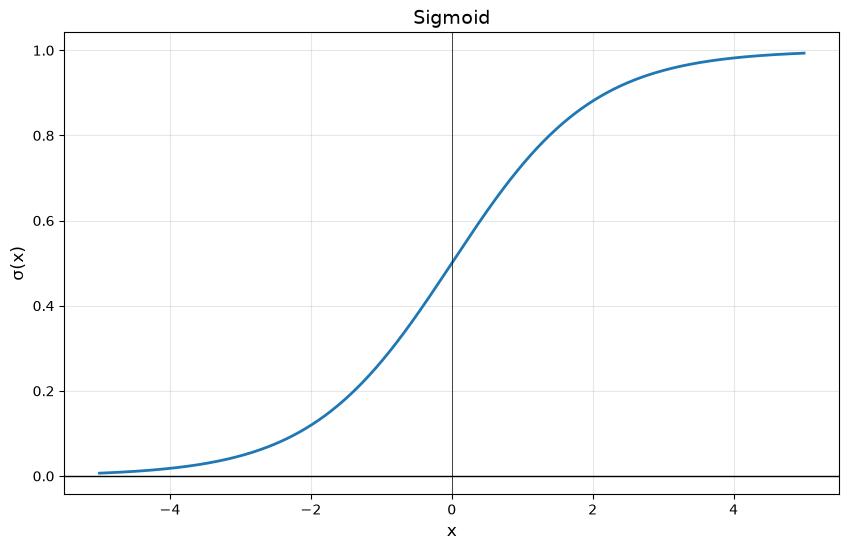

In [3]:
# Define sigmoid function
def sigma(x):
    return 1 / (1 + np.exp(-x))

# Generate and plot
x = np.linspace(-5, 5, 1000)
plt.figure(figsize=(10, 6))
plt.plot(x, sigma(x), linewidth=2)
plt.axhline(y=0, color='k', linewidth=1)
plt.grid(True, alpha=0.3)
plt.xlabel('x', fontsize=12)
plt.ylabel('σ(x)', fontsize=12)
plt.title('Sigmoid', fontsize=14)
plt.axhline(y=0, color='k', linewidth=0.5)
plt.axvline(x=0, color='k', linewidth=0.5)
plt.show()

Now all pieces can be put together. Network has $784$ input neurons, two hidden layers with $16$ neurons and $10$ output neurons. Each layer computes $a^{(l)} = \sigma(W^{(l)} a^{(l-1)} + b^{(l)})$, where $W^{(l)}$ is matrix of weights and $b^{(l)}$ is vector of biases. Weights and biases are initialised randomly, so before training the output is meaningless. The number of parameters is $784 \cdot 16 + 16 \cdot 16 + 16 \cdot 10 + 16 + 16 + 10 = 13002$.

Weight shapes: [(16, 784), (16, 16), (10, 16)]
Bias shapes:   [(16, 1), (16, 1), (10, 1)]
Parameters:    13002
Output activations: [0.3 0.  0.7 0.5 0.5 0.8 0.5 0.9 0.  0.4]
Predicted digit (untrained): 7


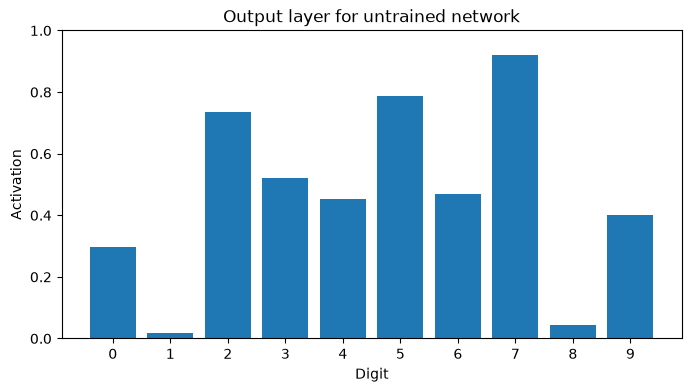

In [4]:
net = Network([784, 16, 16, 10], seed=1)
print("Weight shapes:", [w.shape for w in net.weights])
print("Bias shapes:  ", [b.shape for b in net.biases])
print("Parameters:   ", sum(w.size for w in net.weights) + sum(b.size for b in net.biases))

output = net.feedforward(vector)
print("Output activations:", output.ravel())
print("Predicted digit (untrained):", net.predict(vector))

plt.figure(figsize=(8, 4))
plt.bar(range(10), output.ravel())
plt.xticks(range(10))
plt.ylim(0, 1)
plt.xlabel("Digit")
plt.ylabel("Activation")
plt.title("Output layer for untrained network")
plt.show()

# Training the network

## Cost calculation
To train the network first we need to know what is the ideal result in last layer. For example if we have digit with number $1$ inside the image we need to have output layer with activations $[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]$. That means that neuron with index $1$ is activated and all other neurons are not activated. We are going to achieve that with $ \text{target\_output} $ function. 

In [5]:
def target_output(digit, classes=10):
    """Target output for a digit as a column vector: 1 at the digit, 0 elsewhere."""
    y = np.zeros((classes, 1))
    y[digit] = 1.0
    return y

Once we have target output we can calculate how far off the current result is from the target output. For that $ \text{cost} $ function is implemented.

In [6]:
def cost(output, target):
    """Squared-error cost of one example: 1/2 * sum of (output - target)^2."""
    return 0.5 * np.sum((output - target) ** 2)

Why cost function is squaring the difference between output and target? Squaring the difference has several advantages:
- Ensures that the cost is always non-negative, which is important for optimization.
- Penalizes larger errors more than smaller ones, which can help the model focus on reducing larger mistakes.
- Provides a smooth and continuous gradient, which is useful for gradient-based optimization methods

The ½ is there only to cancel the 2 that appears when we take the derivative in backpropagation. 

To evaluate the network on many images at once, we can average the costs over all examples. For that $ \text{mean\_cost} $ function is implemented.

In [7]:
def mean_cost(network, data):
    """Average cost over `data`, a list of (input_vector, target_vector) pairs."""
    return sum(cost(network.feedforward(x), y) for x, y in data) / len(data)

Mean cost function have two roles:
1. Evaluation: it tells you whether the network is better across all cases, not just one image. You compare it before and after training, or between different network setups.
2. Optimisation target: training doesn't only check this number, it minimises it. The weights are adjusted so the average error across all images goes down, and that is what stops a fix for one image from breaking the others.

Let's put everything together with one example:

In [8]:
# Cost of a single image: image of 0, expected answer is digit 0
target = target_output(0)
print("Target:", target.ravel())
print("Output:", net.feedforward(vector).ravel())
print("Cost of single image:", cost(net.feedforward(vector), target))

# Reference points
print("Cost of perfect output:", cost(target, target))
print("Cost of all outputs 0.5:", cost(np.full((10, 1), 0.5), target))

# Mean cost over one image of each digit (centered set)
data = [(load_image_vector(f"exam/training-dataset/centered/{d}/{d}_0.png"), target_output(d))
        for d in range(10)]
print("Mean cost over 10 images:", mean_cost(net, data))

Target: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Output: [0.3 0.  0.7 0.5 0.5 0.8 0.5 0.9 0.  0.4]
Cost of single image: 1.6788144106722367
Cost of perfect output: 0.0
Cost of all outputs 0.5: 1.25
Mean cost over 10 images: 1.5325065935279683


**Target $  [1, 0, 0, ...] $**  
The correct answer. The image is a 0, so the slider for digit 0 should be at 1 and all the others at 0.

**Output $ [0.3, 0, 0.3, 0.7, 0.6, 0.3, 0.4, 1.0, 0, 0.5]  $**  
What the network actually answered. It is untrained, so its weights are random and the answer is basically a guess.
• The slider for 0 is only at 0.3, but should be 1.
• The slider for 7 is at 1.0, so it is most confident about the wrong digit.

**Cost of single image: 1.47**  
The total mistake for this image. For each slider we take the distance from the target, square it and add everything up (then halve it). Many sliders are wrong, and 0 and 7 are very wrong, so the number is big.

**Cost of perfect output: 0.0**  
If the output equals the target exactly, there is no mistake. This is the best score possible, and training aims for it.

**Cost of all outputs 0.5: 1.25**  
The "I have no idea" answer, where every slider sits in the middle. It still counts as a mistake, 1.25.

**Mean cost over 10 images: 1.54**  
The same mistake score, averaged over one image of each digit. It is similar to the single image, because the network is equally bad everywhere.

## Dataset

Training images are stored as `<variant>/<digit>/<digit>_<n>.png`, so the label of every image is the name of its digit folder. Loader turns each image into a pair of input vector and target output. Variants (`centered`, `different_sizes`, `different_rotations`, `mixed`, `mixed_test`) can be selected, which allows to train on some of them and test on a variant that network has never seen. Variants `mixed` and `mixed_test` combine everything: digits have different placement, size and rotation at the same time. They are generated separately, so `mixed_test` contains different images than `mixed`.

In [9]:
DATASET_DIR = PROJECT_ROOT / "exam" / "training-dataset"


def list_variants():
    return sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir())


def load_dataset(variants=None):
    """Return list of (image_vector, target_output) pairs for given variants (default: all)."""
    data = []
    for variant in variants or list_variants():
        for digit_dir in sorted((DATASET_DIR / variant).iterdir()):
            if not digit_dir.is_dir():
                continue
            digit = int(digit_dir.name)
            for image_path in sorted(digit_dir.glob("*.png")):
                data.append((load_image_vector(image_path), target_output(digit)))
    return data


for variant in list_variants():
    variant_data = load_dataset([variant])
    labels = np.argmax([y for _, y in variant_data], axis=1).ravel()
    print(f"{variant}: {len(variant_data)} images, per digit: {np.bincount(labels)}")

all_data = load_dataset()
print("Total:", len(all_data), "| input:", all_data[0][0].shape, "| target:", all_data[0][1].shape)
print("Mean cost over whole dataset:", mean_cost(net, all_data))

centered: 10 images, per digit: [1 1 1 1 1 1 1 1 1 1]
different_rotations: 100 images, per digit: [10 10 10 10 10 10 10 10 10 10]
different_sizes: 100 images, per digit: [10 10 10 10 10 10 10 10 10 10]
mixed: 100 images, per digit: [10 10 10 10 10 10 10 10 10 10]
mixed_test: 100 images, per digit: [10 10 10 10 10 10 10 10 10 10]
Total: 410 | input: (784, 1) | target: (10, 1)
Mean cost over whole dataset: 1.5148972836734884


## Gradient descent

Cost $C$ depends on all weights and biases of the network ($13002$ numbers). Gradient $\nabla C$ tells for every one of them how much the cost grows if that number is increased a little. To lower the cost every weight and bias is moved a small step in the opposite direction:
$$w \leftarrow w - \eta \frac{\partial C}{\partial w} \qquad b \leftarrow b - \eta \frac{\partial C}{\partial b}$$
where $\eta$ is learning rate, the size of the step. Too small and training is slow, too large and the steps overshoot the minimum. Update is implemented as `Network.gradient_descent_step`.

Efficient way to calculate gradient is **backpropagation**, which is the next step. For now the gradient is estimated numerically: nudge one parameter by tiny $h$ and see how cost changes, $\frac{\partial C}{\partial w} \approx \frac{C(w+h) - C(w-h)}{2h}$. It is too slow for real training (two forward passes per parameter) but it shows gradient descent working, and later it can be used to verify backpropagation.

In [10]:
def numerical_gradient(network, x, y, h=1e-5):
    """Estimate gradient of the cost of one example for every weight and bias."""
    grad_w = [np.zeros_like(w) for w in network.weights]
    grad_b = [np.zeros_like(b) for b in network.biases]
    for params, grads in ((network.weights, grad_w), (network.biases, grad_b)):
        for p, g in zip(params, grads):
            for i in np.ndindex(p.shape):
                original = p[i]
                p[i] = original + h
                cost_up = cost(network.feedforward(x), y)
                p[i] = original - h
                cost_down = cost(network.feedforward(x), y)
                p[i] = original
                g[i] = (cost_up - cost_down) / (2 * h)
    return grad_w, grad_b


# Train a copy on a single image (digit 0) so the original network stays untouched
trained = copy.deepcopy(net)
target = target_output(0)
eta = 1.0

for step in range(21):
    if step % 5 == 0:
        print(f"step {step:2d}: cost = {cost(trained.feedforward(vector), target):.4f}, predicted digit = {trained.predict(vector)}")
    grad_w, grad_b = numerical_gradient(trained, vector, target)
    trained.gradient_descent_step(grad_w, grad_b, eta)

step  0: cost = 1.6788, predicted digit = 7
step  5: cost = 0.0734, predicted digit = 0
step 10: cost = 0.0298, predicted digit = 0
step 15: cost = 0.0186, predicted digit = 0
step 20: cost = 0.0135, predicted digit = 0


## Backpropagation

Numerical gradient needs two forward passes for every one of $13002$ parameters. Backpropagation gets all of them with one forward and one backward pass, using the chain rule. Weighted input of a neuron is $z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}$ and activation is $a^{(l)} = \sigma(z^{(l)})$. For every layer an error $\delta^{(l)}$ is calculated, which tells how much cost changes when $z^{(l)}$ changes.

1. **Forward pass.** Run the network and remember $z^{(l)}$ and $a^{(l)}$ of every layer.
2. **Output layer error.** Difference between output and target, scaled by how sensitive the neuron is to its input: $\delta^{(L)} = (a^{(L)} - y) \odot \sigma'(z^{(L)})$, where $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ and $\odot$ is element-wise multiplication.
3. **Go backwards.** Error of a layer is the error of the next layer sent back through the same weights: $\delta^{(l)} = \left( (W^{(l+1)})^T \delta^{(l+1)} \right) \odot \sigma'(z^{(l)})$.
4. **Gradients.** $\frac{\partial C}{\partial b^{(l)}} = \delta^{(l)}$ and $\frac{\partial C}{\partial W^{(l)}} = \delta^{(l)} \left( a^{(l-1)} \right)^T$. Weight is changed more when the neuron it feeds has a large error and the neuron it comes from was strongly active.

It is implemented as `Network.backprop` and `sigma_prime` in `activations.py`. To verify it, its gradient is compared with the numerical one on the same example.

In [11]:
target = target_output(0)

bp_grad_w, bp_grad_b = net.backprop(vector, target)
num_grad_w, num_grad_b = numerical_gradient(net, vector, target)

for layer in range(len(net.weights)):
    max_diff_w = np.max(np.abs(bp_grad_w[layer] - num_grad_w[layer]))
    max_diff_b = np.max(np.abs(bp_grad_b[layer] - num_grad_b[layer]))
    print(f"layer {layer + 1}: max difference weights = {max_diff_w:.2e}, biases = {max_diff_b:.2e}")

layer 1: max difference weights = 4.61e-11, biases = 3.26e-11
layer 2: max difference weights = 3.41e-11, biases = 2.02e-11
layer 3: max difference weights = 2.11e-11, biases = 1.23e-11


## Training with mini-batch stochastic gradient descent

Now all parts can be put together. Calculating the gradient over the whole dataset for every single step would be slow, and one image alone gives a noisy direction. Compromise is **mini-batch SGD**:

1. Shuffle the training data, so batches differ in every epoch.
2. Split it into batches of small size (here $10$ images).
3. For every batch calculate gradient of each image with backpropagation, average them and take one gradient descent step.
4. When all batches are used one **epoch** is finished. Repeat for several epochs.

After every epoch the accuracy (share of images where the neuron with the highest activation is the correct digit) is measured on training data and on test data. It is implemented as `Network.train` and `Network.accuracy`.

Network is trained on `centered`, `different_sizes`, `different_rotations` and `mixed` variants and tested on `mixed_test`, which it has never seen. In these images digits have different placement, size and rotation at the same time, but the network has already seen similar combinations in `mixed`, so this tests how well it generalises to new images of the same kind.

In [12]:
training_data = load_dataset(["centered", "different_sizes", "different_rotations", "mixed"])
test_data = load_dataset(["mixed_test"])
print(f"Training images: {len(training_data)}, test images: {len(test_data)}")

digit_net = Network([784, 16, 16, 10], seed=1)
print(f"Before training: train accuracy = {digit_net.accuracy(training_data):.2%}, test accuracy = {digit_net.accuracy(test_data):.2%}")

history = digit_net.train(training_data, epochs=30, batch_size=10, eta=3.0, test_data=test_data, seed=0)
print(f"Mean cost: train = {mean_cost(digit_net, training_data):.4f}, test = {mean_cost(digit_net, test_data):.4f}")

Training images: 310, test images: 100
Before training: train accuracy = 10.00%, test accuracy = 9.00%
epoch   1: train accuracy = 26.13%, test accuracy = 2.00%
epoch   2: train accuracy = 28.39%, test accuracy = 8.00%
epoch   3: train accuracy = 35.16%, test accuracy = 4.00%
epoch   4: train accuracy = 33.23%, test accuracy = 10.00%
epoch   5: train accuracy = 43.23%, test accuracy = 9.00%
epoch   6: train accuracy = 49.35%, test accuracy = 10.00%
epoch   7: train accuracy = 57.74%, test accuracy = 12.00%
epoch   8: train accuracy = 60.65%, test accuracy = 7.00%
epoch   9: train accuracy = 69.68%, test accuracy = 13.00%
epoch  10: train accuracy = 73.23%, test accuracy = 10.00%
epoch  11: train accuracy = 73.23%, test accuracy = 11.00%
epoch  12: train accuracy = 76.13%, test accuracy = 10.00%
epoch  13: train accuracy = 77.74%, test accuracy = 9.00%
epoch  14: train accuracy = 79.35%, test accuracy = 10.00%
epoch  15: train accuracy = 79.35%, test accuracy = 12.00%
epoch  16: train a

### Summary of testing results

- The network has $784$ input neurons, two hidden layers with $16$ neurons and $10$ output neurons. It was trained for $30$ epochs with batches of $10$ images and learning rate $3.0$.
- Before training the network was only guessing: about $10\%$ of images were recognised correctly, which is the same as picking a random digit out of ten.
- After training the network recognises about $86\%$ of the images it was trained on. Average cost on them dropped from about $1.5$ to about $0.09$. So the network does learn.
- On new images it has never seen (`mixed_test`, digits with different placement, size and rotation) it recognises only about $10\%$. That is no better than guessing. Average cost on them is about $0.58$.
- The network learned the training images but not what digits look like in general. Every first layer neuron is connected to one fixed pixel, so when a digit moves, changes size or rotates, different pixels light up and what the network learned does not help. With only $310$ training images it also has too few examples to cover all those variations.
- Conclusion: simple network works as a proof of concept, but it is not good enough for digits that vary in placement, size and rotation. More training data, a different number of layers and neurons or a different type of network (for example convolutional) will be tested in the experiments.

## Analysis of training

Backpropagation was already verified against the numerical gradient. To analyse the training itself, cost and accuracy are recorded after every epoch, on training data and on test data, and plotted. Training curves show how fast the network learns. When training curve keeps improving and the test curve does not, the network is memorising the training images instead of learning general rules.

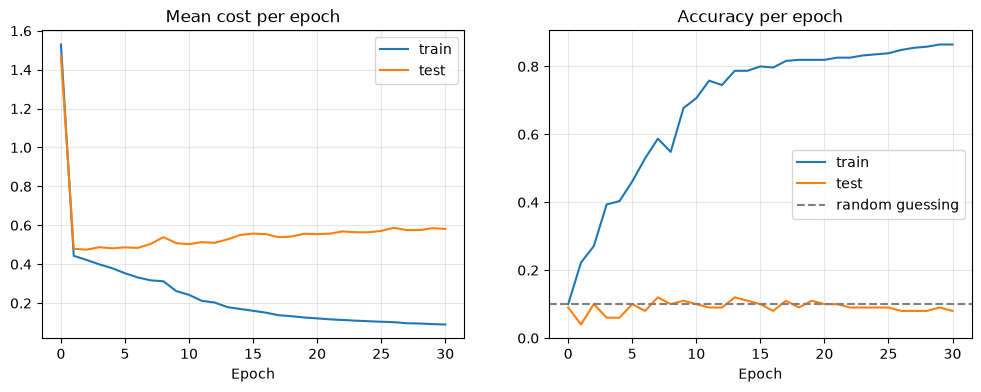

In [13]:
def train_and_track(sizes, epochs=30, batch_size=10, eta=3.0, seed=1, hidden_activation="sigmoid"):
    """Train a new network and record cost and accuracy on train and test data after every epoch."""
    network = Network(sizes, seed=seed, hidden_activation=hidden_activation)
    history = {"train_cost": [], "test_cost": [], "train_accuracy": [], "test_accuracy": []}

    def record():
        history["train_cost"].append(mean_cost(network, training_data))
        history["test_cost"].append(mean_cost(network, test_data))
        history["train_accuracy"].append(network.accuracy(training_data))
        history["test_accuracy"].append(network.accuracy(test_data))

    record()  # epoch 0: before training
    for epoch in range(epochs):
        network.train(training_data, 1, batch_size, eta, seed=seed * 1000 + epoch, verbose=False)
        record()
    return history


baseline = train_and_track([784, 16, 16, 10])

fig, (ax_cost, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_cost.plot(baseline["train_cost"], label="train")
ax_cost.plot(baseline["test_cost"], label="test")
ax_cost.set_title("Mean cost per epoch")
ax_acc.plot(baseline["train_accuracy"], label="train")
ax_acc.plot(baseline["test_accuracy"], label="test")
ax_acc.axhline(0.1, color="gray", linestyle="--", label="random guessing")
ax_acc.set_title("Accuracy per epoch")
for ax in (ax_cost, ax_acc):
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()

## Experiment: number of layers and neurons

Same data, same training settings (30 epochs, batches of 10, learning rate 3.0) with different network shapes: no hidden layer, one hidden layer, two hidden layers, wider layers and three hidden layers. Random initial weights influence the result, so every shape is trained 3 times with different initial weights and the average is shown.

layers                            params  train acc  test acc  train cost  test cost
[784, 10]                           7850      36.5%      9.3%       0.338      0.682
[784, 16, 10]                      12730      84.0%     11.0%       0.107      0.592
[784, 16, 16, 10]                  13002      84.4%      8.7%       0.107      0.571
[784, 32, 32, 10]                  26506      84.2%     12.0%       0.093      0.571
[784, 64, 10]                      50890      64.2%     10.3%       0.190      0.595
[784, 64, 32, 16, 10]              53018      93.3%      9.7%       0.047      0.592
[784, 16, 16, 16, 16, 16, 10]      13818      65.9%      9.3%       0.245      0.590
[784, 48, 48, 48, 48, 48, 10]      47578      36.9%      8.7%       0.394      0.591
[784, 784, 10]                    623290      12.9%     11.7%       0.610      0.636


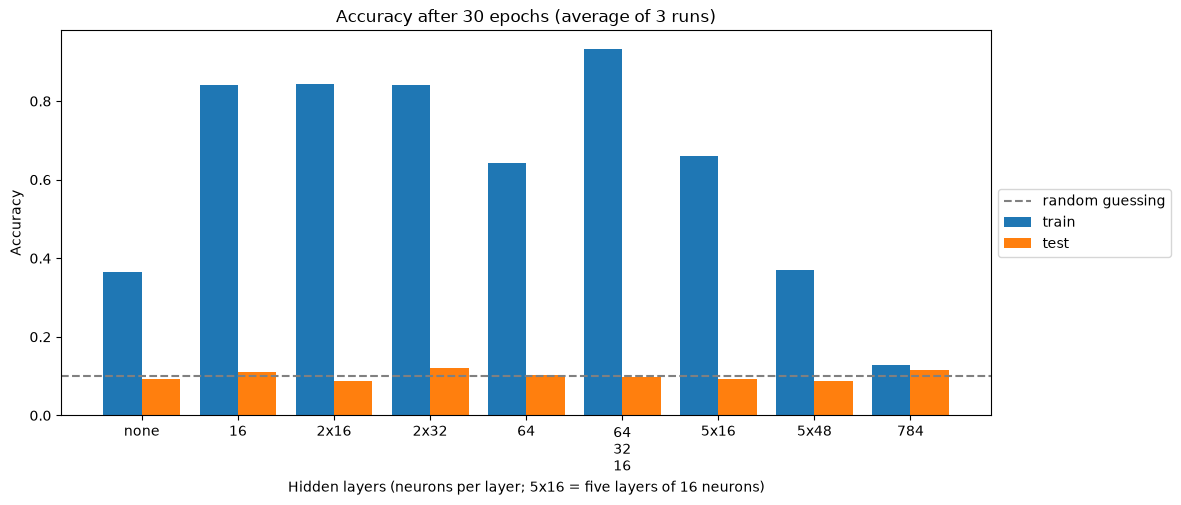

In [14]:
architectures = [
    [784, 10],
    [784, 16, 10],
    [784, 16, 16, 10],
    [784, 32, 32, 10],
    [784, 64, 10],
    [784, 64, 32, 16, 10],
    [784, 16, 16, 16, 16, 16, 10],
    [784, 48, 48, 48, 48, 48, 10],
    [784, 784, 10],
]
seeds = [1, 2, 3]

results = []
for sizes in architectures:
    runs = [train_and_track(sizes, seed=seed) for seed in seeds]
    results.append({
        "sizes": sizes,
        "parameters": sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])),
        "train_accuracy": np.mean([run["train_accuracy"][-1] for run in runs]),
        "test_accuracy": np.mean([run["test_accuracy"][-1] for run in runs]),
        "train_cost": np.mean([run["train_cost"][-1] for run in runs]),
        "test_cost": np.mean([run["test_cost"][-1] for run in runs]),
    })

print(f"{'layers':<32}{'params':>8}{'train acc':>11}{'test acc':>10}{'train cost':>12}{'test cost':>11}")
for r in results:
    print(f"{str(r['sizes']):<32}{r['parameters']:>8}{r['train_accuracy']:>11.1%}{r['test_accuracy']:>10.1%}"
          f"{r['train_cost']:>12.3f}{r['test_cost']:>11.3f}")

def layers_label(sizes):
    """Short label of hidden layers, e.g. 5x16 for five layers of 16 neurons."""
    hidden = sizes[1:-1]
    if not hidden:
        return "none"
    if len(set(hidden)) == 1 and len(hidden) > 1:
        return f"{len(hidden)}x{hidden[0]}"
    return "\n".join(str(n) for n in hidden)


labels = [layers_label(r["sizes"]) for r in results]
positions = np.arange(len(results))
plt.figure(figsize=(12, 5))
plt.bar(positions - 0.2, [r["train_accuracy"] for r in results], width=0.4, label="train")
plt.bar(positions + 0.2, [r["test_accuracy"] for r in results], width=0.4, label="test")
plt.axhline(0.1, color="gray", linestyle="--", label="random guessing")
plt.xticks(positions, labels)
plt.xlabel("Hidden layers (neurons per layer; 5x16 = five layers of 16 neurons)")
plt.ylabel("Accuracy")
plt.title("Accuracy after 30 epochs (average of 3 runs)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## Experiment: ReLU instead of sigmoid

Sigmoid squashes every value into $(0, 1)$ and its slope is at most $0.25$. This is what made deep networks hard to train. ReLU is simpler:

$$\text{ReLU}(x) = \max(0, x)$$

Its slope is $1$ for $x > 0$ and $0$ otherwise, so the error is not shrunk when it goes back through a layer. Here ReLU replaces sigmoid in the hidden layers. The output layer stays sigmoid, so the output is still between $0$ and $1$ and the cost function does not change.

Two things had to change for ReLU:
- Weights start small ($\text{normal} \cdot \sqrt{2 / n_{in}}$) and biases start at $0$. With plain random weights and $784$ inputs, the values are huge and the network does not learn at all.
- Learning rate is $0.5$ instead of $3.0$, because ReLU values are not limited to $1$ and big steps make training unstable.

layers                            sigmoid train  sigmoid test  relu train  relu test
[784, 16, 10]                             84.0%         11.0%       95.7%      12.7%
[784, 16, 16, 10]                         84.4%          8.7%       92.8%      11.0%
[784, 64, 32, 16, 10]                     93.3%          9.7%       93.9%      12.0%
[784, 16, 16, 16, 16, 16, 10]             65.9%          9.3%       89.8%      13.7%
[784, 48, 48, 48, 48, 48, 10]             36.9%          8.7%       97.6%      13.7%
[784, 784, 10]                            12.9%         11.7%       99.4%      11.7%


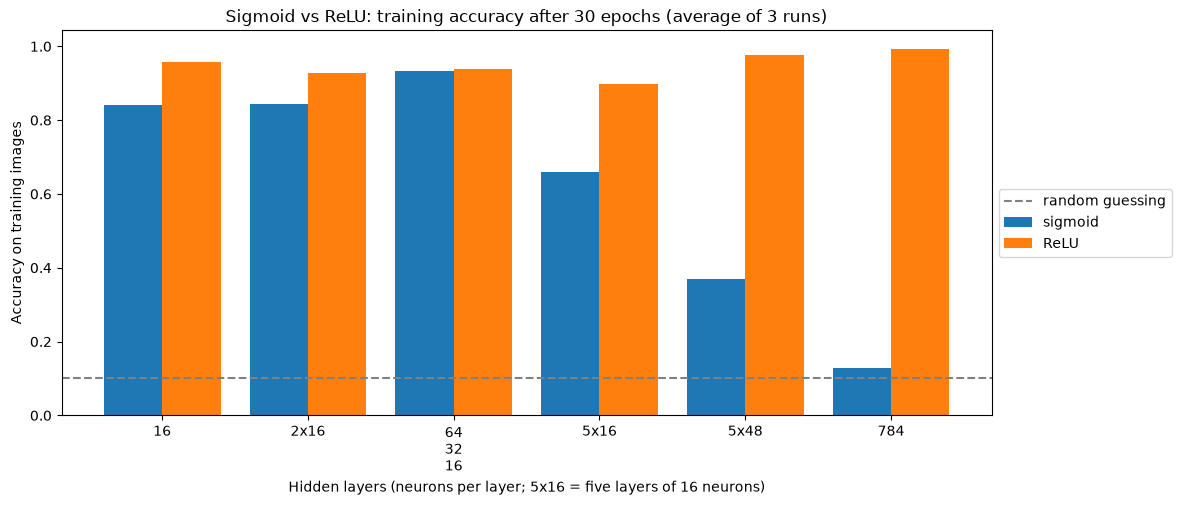

In [15]:
relu_experiment = [
    [784, 16, 10],
    [784, 16, 16, 10],
    [784, 64, 32, 16, 10],
    [784, 16, 16, 16, 16, 16, 10],
    [784, 48, 48, 48, 48, 48, 10],
    [784, 784, 10],
]
settings = {"sigmoid": 3.0, "relu": 0.5}  # learning rate for each activation

relu_results = []
for sizes in relu_experiment:
    row = {"sizes": sizes}
    for activation, eta in settings.items():
        runs = [train_and_track(sizes, eta=eta, seed=seed, hidden_activation=activation) for seed in seeds]
        row[activation] = {
            "train_accuracy": np.mean([run["train_accuracy"][-1] for run in runs]),
            "test_accuracy": np.mean([run["test_accuracy"][-1] for run in runs]),
        }
    relu_results.append(row)

print(f"{'layers':<32}{'sigmoid train':>15}{'sigmoid test':>14}{'relu train':>12}{'relu test':>11}")
for r in relu_results:
    print(f"{str(r['sizes']):<32}{r['sigmoid']['train_accuracy']:>15.1%}{r['sigmoid']['test_accuracy']:>14.1%}"
          f"{r['relu']['train_accuracy']:>12.1%}{r['relu']['test_accuracy']:>11.1%}")

positions = np.arange(len(relu_results))
plt.figure(figsize=(12, 5))
plt.bar(positions - 0.2, [r["sigmoid"]["train_accuracy"] for r in relu_results], width=0.4, label="sigmoid")
plt.bar(positions + 0.2, [r["relu"]["train_accuracy"] for r in relu_results], width=0.4, label="ReLU")
plt.axhline(0.1, color="gray", linestyle="--", label="random guessing")
plt.xticks(positions, [layers_label(r["sizes"]) for r in relu_results])
plt.xlabel("Hidden layers (neurons per layer; 5x16 = five layers of 16 neurons)")
plt.ylabel("Accuracy on training images")
plt.title("Sigmoid vs ReLU: training accuracy after 30 epochs (average of 3 runs)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

### Summary of analysis and experiments

**Training curves**
- Cost on training images goes down from about $1.5$ to $0.09$ and accuracy goes up to about $86\%$. The network learns.
- Cost on test images drops in the first epoch and then stays around $0.5$, even rising a bit while training cost keeps falling. The network is memorising the training images.
- Test accuracy stays around $10\%$ the whole time. That is random guessing.

**Layers and neurons**
- No hidden layer: weakest result, only about $36\%$ on training images.
- One hidden layer with $16$ neurons is already enough for about $84\%$. A second layer or more neurons does not add much. The best one was $64-32-16$ with about $93\%$.
- Five hidden layers did worse: about $66\%$ with $16$ neurons per layer and about $37\%$ with $48$.
- One hidden layer with $784$ neurons barely learned at all, about $14\%$.
- On test images every shape gets $9-12\%$.

**ReLU instead of sigmoid**
- ReLU fixed the networks that sigmoid could not train. Five layers of $48$ went from about $37\%$ to about $98\%$ on training images, and the $784$ neuron layer from about $14\%$ to about $99\%$. So the problem was sigmoid, not the network size.
- ReLU needed small starting weights and a smaller learning rate. Without them nothing was learned.
- On test images ReLU is still only $11-13\%$. A better activation function does not solve the problem with moved, resized or rotated digits.

**Conclusion**
Making the network bigger or deeper did not help, and neither did ReLU on test images. Each first layer neuron looks at one fixed pixel, so when a digit moves, changes size or rotates, the network sees a completely different input. To do better it needs much more varied training data or a different type of network, such as a convolutional one.

# References
1. Video - Sanderson, G. (2017) "But what is a neural network? | Deep learning chapter 1" [https://www.youtube.com/watch?v=aircAruvnKk](https://www.youtube.com/watch?v=aircAruvnKk)
2. Online book - Nielsen, M. (2019) "Neural Networks and Deep Learning" [https://neuralnetworksanddeeplearning.com/](https://neuralnetworksanddeeplearning.com/)
3. Article - Kazuya, I. (2024) |Batch, Mini-Batch & Stochastic Gradient Descent" -  https://dev.to/hyperkai/batch-mini-batch-stochastic-gradient-descent-5ep7

# Used resources
1. GitHub Copilot - Caude Sonet Model 
- code to generate training data set.
- image util to load image and convert it to matrix and vector.
- Random number generator to generate random weights and biases.
- Dataset loader to load training data set.
